In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

DATA_DIR = Path(r"D:\F20DL CW UG\Insurance-Fraud-Detection\Insurance-Fraud-Detection")
RESULTS = Path("../results/images")

CLASSES = ["Fraud", "Non-Fraud"]

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED) # Sets the random seed for TensorFlow (reproducibility of results)

print("TensorFlow version:", tf.__version__)
print("Dataset found:", DATA_DIR.exists())
print("GPU available:", tf.config.list_physical_devices("GPU")) # checks whether TensorFlow can use graphics card to train faster

TensorFlow version: 2.21.0
Dataset found: True
GPU available: []


In [2]:
from sklearn.model_selection import train_test_split

## Function to list all image files in a given folder
def list_images(folder):
    files = []
    for f in folder.iterdir(): # loops over all files in folder
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            files.append(str(f))
    return files

# Function to get the paths and labels of images in a given split (train/test)
def get_paths_and_labels(split):
    paths = []
    labels = []
    for c in CLASSES: 
        files = list_images(DATA_DIR / split / c) #
        paths += files
        if c == "Fraud":
            labels += [1] * len(files) # adds a label of 1 for each fraud image
        else:
            labels += [0] * len(files) # adds a label of 0 for each non-fraud image
    return paths, labels

train_paths, train_labels = get_paths_and_labels("train") # gets the paths and labels for the training set
test_paths, test_labels = get_paths_and_labels("test") # gets the paths and labels for the test set

# Splits the training set into a training and validation set
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels,
    test_size=0.15, # 15% of the training data will be used for validation
    stratify=train_labels, # ensures the same proportion of fraud and non-fraud images in both sets
    random_state=SEED # sets the random seed for reproducibility
)

# Prints the number of images and fraud cases in each set
print("Train:     ", len(train_paths), "images,", sum(train_labels), "fraud")
print("Validation:", len(val_paths), "images,", sum(val_labels), "fraud")
print("Test:      ", len(test_paths), "images,", sum(test_labels), "fraud")

Train:      4420 images, 170 fraud
Validation: 780 images, 30 fraud
Test:       1416 images, 93 fraud


In [3]:
# Function to load and resize an image given its path and label
def load_and_resize(path, label):
    img = tf.io.read_file(path) # Read the image file
    img = tf.io.decode_image(img, channels=3, expand_animations=False) # Decode the image
    img = tf.image.resize(img, IMG_SIZE) # Resize the image
    img = tf.cast(img, tf.uint8) # Cast the image to uint8
    return img, label

# Function to normalise an image given its label
def normalise(img, label):
    img = tf.cast(img, tf.float32) / 255.0 # Normalise the image to [0, 1]
    return img, label

# Function to create a TensorFlow dataset from image paths and labels
def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)) # creates a dataset
    ds = ds.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE) # applies the load_and_resize function in parallel
    ds = ds.cache() # caches the dataset in memory for faster access

    # If shuffle is True, shuffle the dataset with a buffer size equal to the number of paths
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED) 
    ds = ds.map(normalise) 
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, shuffle=True) # creates the training dataset
val_ds = make_dataset(val_paths, val_labels) # creates the validation dataset
test_ds = make_dataset(test_paths, test_labels) # creates the test dataset

# Prints the shape of one batch of images and labels, and the range of pixel values
images, labels = next(iter(train_ds))
print("One batch of images:", images.shape)
print("One batch of labels:", labels.shape)
print("Pixel values from", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

One batch of images: (32, 128, 128, 3)
One batch of labels: (32,)
Pixel values from 0.0 to 1.0


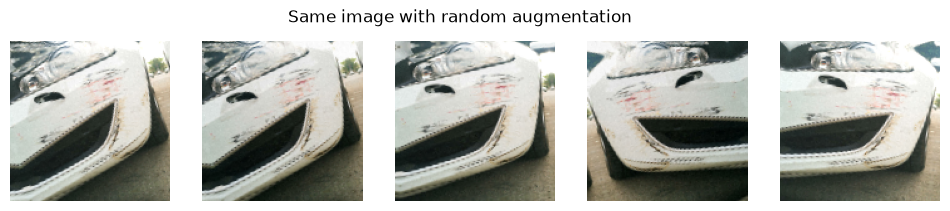

Class weights: {0: 0.52, 1: 13.0}


In [4]:
from tensorflow.keras import layers

# Data augmentation pipeline using Keras Sequential API
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"), # randomly flips the image horizontally
    layers.RandomRotation(0.05), # randomly rotates the image by up to 5% of 360 degrees
    layers.RandomBrightness(0.1, value_range=(0, 1)), # randomly adjusts the brightness of the image by up to 10%
], name="augmentation")

sample_img = images[0] # Select a sample image from the dataset
plt.figure(figsize=(12, 2.3)) # Create a figure with a specific size
for i in range(5): # Loop to create 5 augmented versions of the sample image
    aug = data_augmentation(tf.expand_dims(sample_img, 0), training=True) # Applies augmentation
    plt.subplot(1, 5, i + 1) # Create a subplot for each augmented image
    plt.imshow(aug[0]) 
    plt.axis("off")
plt.suptitle("Same image with random augmentation") 
plt.savefig(RESULTS / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# Calculate class weights to handle class imbalance
n_total = len(train_labels)
n_fraud = sum(train_labels)
n_non_fraud = n_total - n_fraud
class_weight = {  # calculates the class weights for the two classes (0: non-fraud, 1: fraud)
    0: n_total / (2 * n_non_fraud),
    1: n_total / (2 * n_fraud),
}
print("Class weights:", class_weight)

In [5]:
from tensorflow.keras import models

# Function to build a CNN model
def build_cnn(filters=[32, 64, 128], dense_units=64, dropout=0.3, name="fraud_detection_cnn_v1"):
    model = models.Sequential(name=name) 
    model.add(layers.Input(shape=IMG_SIZE + (3,))) # Input layer
    model.add(data_augmentation)

    # Adds convolutional layers with specified filters, batch normalization, and max pooling
    for f in filters:
        model.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())

    # Adds global average pooling, dense, and dropout layers
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(dense_units, activation="relu"))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

# Build the CNN model and print its summary
model = build_cnn()
model.summary()

Model: "fraud_detection_cnn_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,465 (400.25 KB)

 Trainable params: 102,017 (398.50 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
# Compiles the model with Adam optimizer, binary crossentropy loss, and metrics for precision, recall, and PR AUC
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Adam optimizer with a learning rate of 0.001
    loss="binary_crossentropy", #
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

# Sets up early stopping to monitor validation PR AUC and stop training if it doesn't improve for 5 epochs
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
)

# Trains the model using the training dataset, validation dataset, class weights, and early stopping
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, # Number of epochs to train the model
    class_weight=class_weight,
    callbacks=[early_stop],
)

# Saves the trained model to the specified directory
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)
model.save(MODELS / "fraud_detection_cnn_v1.keras")

Epoch 1/30


d:\F20DL CW UG\f20dl-vehicle-fraud-ug-group9\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


139/139 ━━━━━━━━━━━━━━━━━━━━ 71s 494ms/step - loss: 0.7756 - pr_auc: 0.0567 - precision: 0.0500 - recall: 0.5294 - val_loss: 0.2805 - val_pr_auc: 0.0865 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 67s 478ms/step - loss: 0.6605 - pr_auc: 0.0876 - precision: 0.0624 - recall: 0.6471 - val_loss: 0.3937 - val_pr_auc: 0.0404 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 66s 476ms/step - loss: 0.6558 - pr_auc: 0.0728 - precision: 0.0660 - recall: 0.6588 - val_loss: 0.3443 - val_pr_auc: 0.1092 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 65s 470ms/step - loss: 0.6813 - pr_auc: 0.0710 - precision: 0.0595 - recall: 0.5882 - val_loss: 0.6046 - val_pr_auc: 0.0862 - val_precision: 0.0702 - val_recall: 0.5333
Epoch 5/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 65s 465ms/step - loss: 0.6417 - pr_auc: 0.0954 - precision: 0.0645 - recall: 0.7059 - val_loss: 1.1183 - val_pr

In [18]:
# Building CNN v2 with Oversampling: balanced training set (about 50% fraud in every batch)
fraud_paths = [p for p, l in zip(train_paths, train_labels) if l == 1]
non_fraud_paths = [p for p, l in zip(train_paths, train_labels) if l == 0]

# Function to create a dataset for a specific class (fraud or non-fraud) with oversampling
def make_class_dataset(paths, label):
    ds = tf.data.Dataset.from_tensor_slices((paths, [label] * len(paths))) 
    ds = ds.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE) 
    ds = ds.cache()
    ds = ds.shuffle(len(paths), seed=SEED) 
    ds = ds.repeat()
    return ds

# Creates separate datasets for fraud and non-fraud classes
fraud_ds = make_class_dataset(fraud_paths, 1)
non_fraud_ds = make_class_dataset(non_fraud_paths, 0)

# Creates a balanced dataset by sampling from the fraud and non-fraud datasets with equal weights
balanced_ds = tf.data.Dataset.sample_from_datasets(
    [fraud_ds, non_fraud_ds], weights=[0.5, 0.5], seed=SEED
)
balanced_ds = balanced_ds.map(normalise).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

steps_per_epoch = len(train_paths) // BATCH_SIZE # Calculates the number of steps per epoch

# Check that a batch is roughly balanced
_, sample_labels = next(iter(balanced_ds))
print("Fraud in one batch:", int(tf.reduce_sum(sample_labels)), "of", BATCH_SIZE)

# Builds and train CNN v2 (same architecture as v1, no class weights)
model_v2 = build_cnn(name="fraud_detection_cnn_v2")
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

early_stop_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True
)

history_v2 = model_v2.fit(
    balanced_ds,
    validation_data=val_ds,
    epochs=30,
    steps_per_epoch=steps_per_epoch,
    callbacks=[early_stop_v2],
)

model_v2.save(MODELS / "fraud_detection_cnn_v2.keras")

Fraud in one batch: 15 of 32
Epoch 1/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 81s 576ms/step - loss: 0.6402 - pr_auc: 0.6756 - precision: 0.6468 - recall: 0.6392 - val_loss: 0.3773 - val_pr_auc: 0.0451 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 78s 566ms/step - loss: 0.5808 - pr_auc: 0.7478 - precision: 0.6995 - recall: 0.7076 - val_loss: 0.1896 - val_pr_auc: 0.0741 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 78s 568ms/step - loss: 0.5475 - pr_auc: 0.7850 - precision: 0.7310 - recall: 0.7178 - val_loss: 0.1831 - val_pr_auc: 0.0626 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 60s 433ms/step - loss: 0.5227 - pr_auc: 0.8094 - precision: 0.7433 - recall: 0.7639 - val_loss: 0.3083 - val_pr_auc: 0.1818 - val_precision: 0.2368 - val_recall: 0.3000
Epoch 5/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 57s 412ms/step - loss: 0.4853 - pr_auc: 0.8392 - precision: 0.7608 - re

In [19]:
import json

# Saves the training history of both models to JSON files
with open(RESULTS / "history_v1.json", "w") as f:
    json.dump(history.history, f)
with open(RESULTS / "history_v2.json", "w") as f:
    json.dump(history_v2.history, f)

print("Saved v1 epochs:", len(history.history["loss"]), "| v2 epochs:", len(history_v2.history["loss"]))

Saved v1 epochs: 13 | v2 epochs: 21


In [5]:
import json

# Loads the trained models and their training histories from files
MODELS = Path("../models")

model = tf.keras.models.load_model(MODELS / "fraud_detection_cnn_v1.keras")
model_v2 = tf.keras.models.load_model(MODELS / "fraud_detection_cnn_v2.keras")

with open(RESULTS / "history_v1.json") as f:
    hist_v1 = json.load(f)
with open(RESULTS / "history_v2.json") as f:
    hist_v2 = json.load(f)

print("Loaded v1:", len(hist_v1["loss"]), "epochs | v2:", len(hist_v2["loss"]), "epochs")

Loaded v1: 13 epochs | v2: 21 epochs


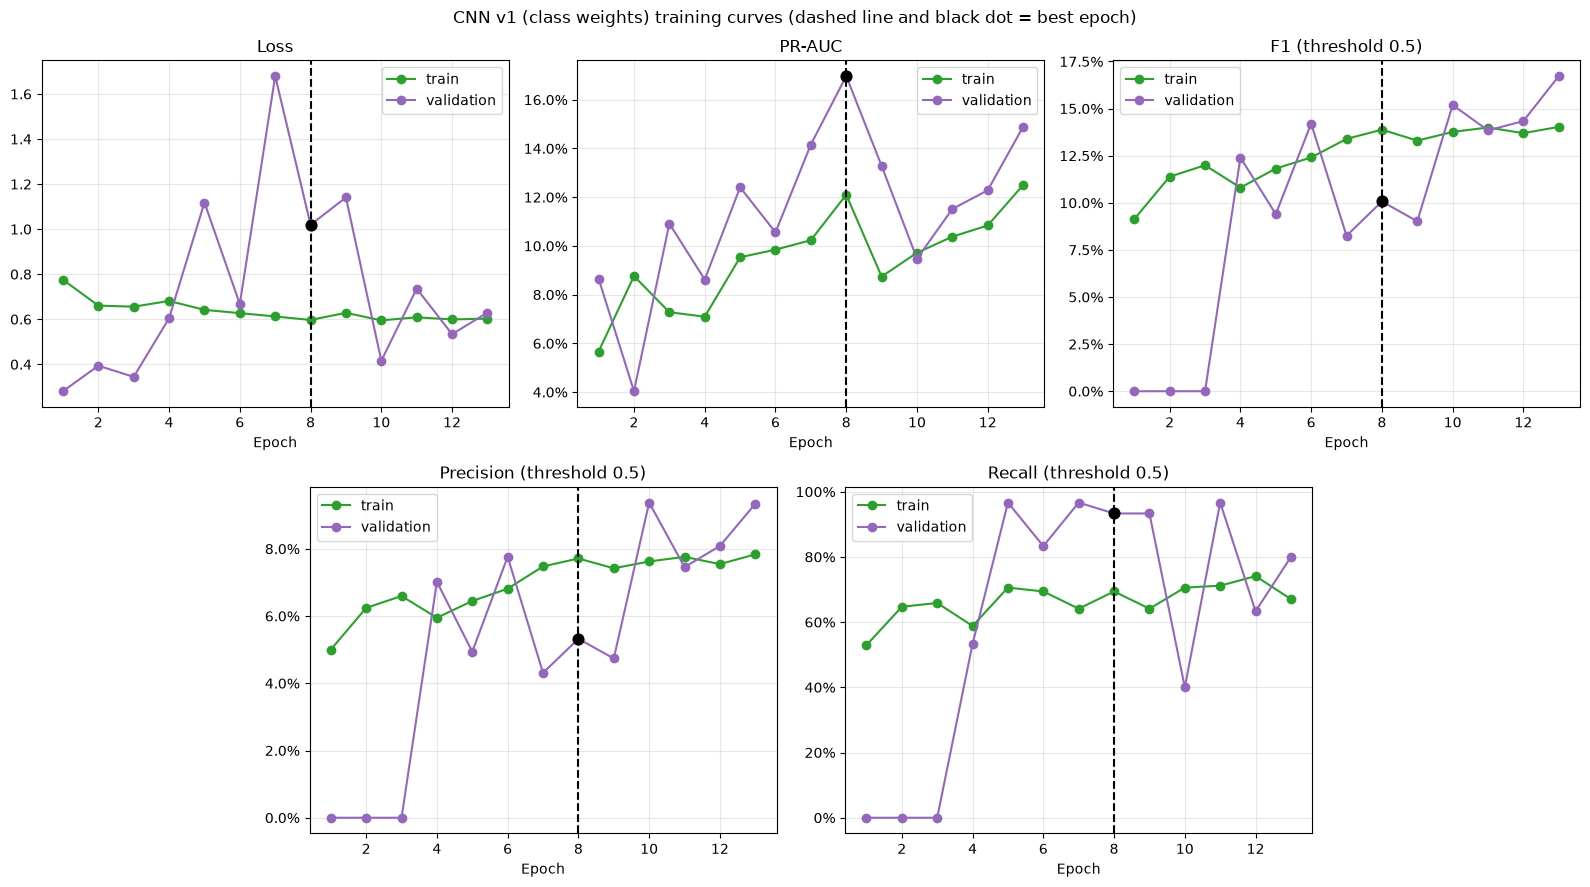

Best epoch: 8 | val PR-AUC: 17.0%


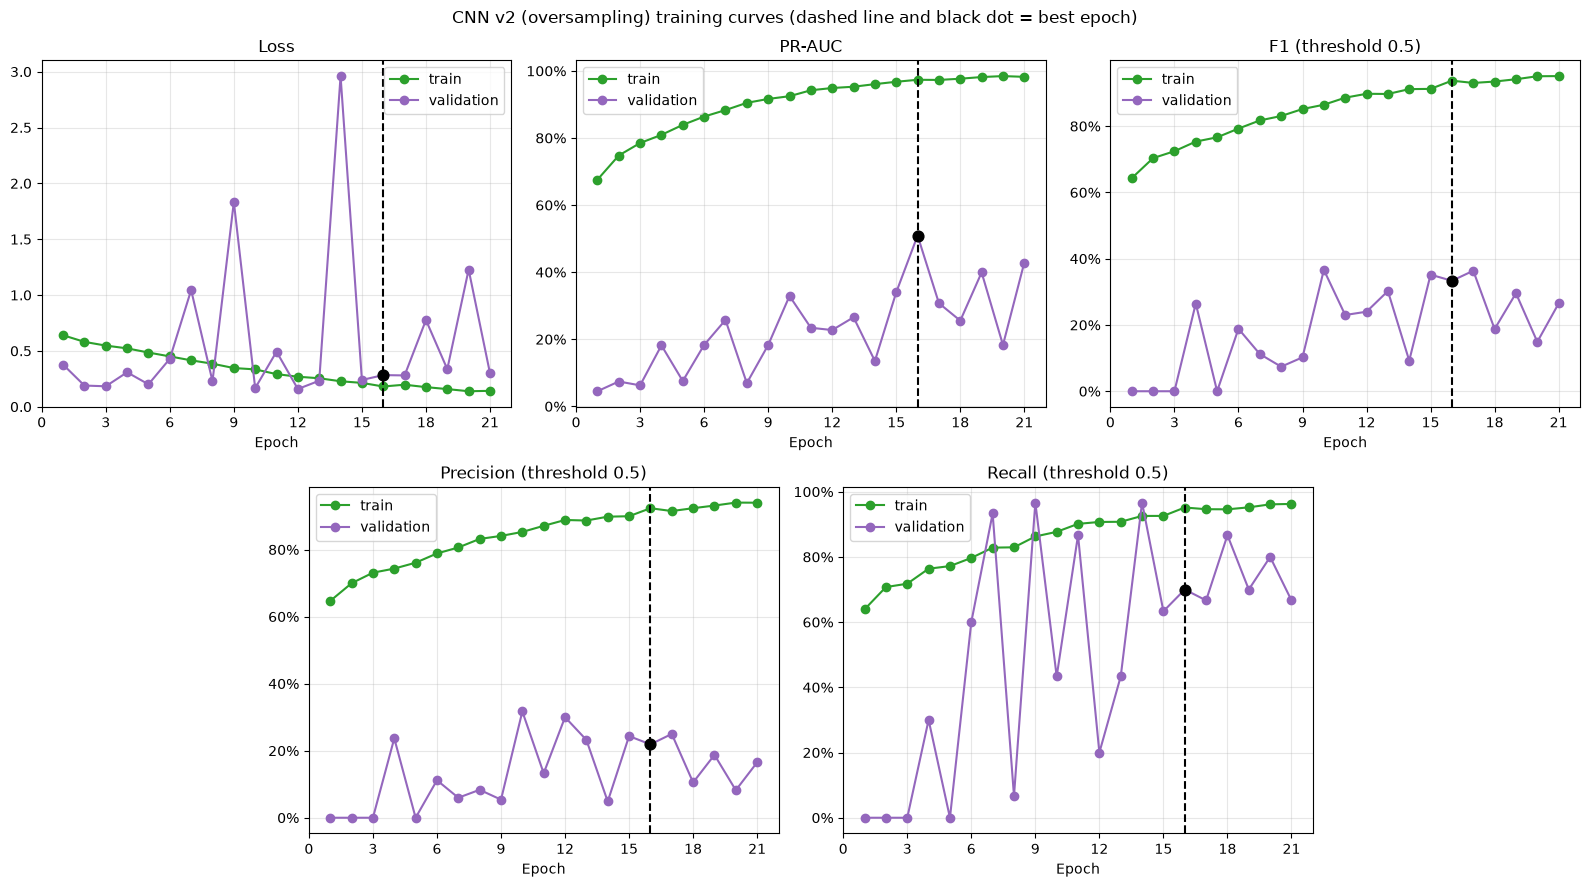

Best epoch: 16 | val PR-AUC: 50.9%


In [8]:
# Plots the training curves for both CNN models using one reusable function.
# CNN v1 (class weights) and CNN v2 (oversampling) are plotted in the same style for a fair comparison.
# Each figure shows loss, PR-AUC, F1, precision and recall per epoch (train vs validation).
# Figures are saved to results.
from matplotlib.ticker import MaxNLocator, PercentFormatter

# Calculates F1 for each epoch from precision and recall
def f1_from(p, r):
    f1 = []
    for i in range(len(p)): 
        if p[i] + r[i] == 0:
            f1.append(0)
        else:
            f1.append(2 * p[i] * r[i] / (p[i] + r[i]))
    return f1

# Plots loss, PR-AUC, F1, precision and recall for one model
def plot_training_curves(hist, title, filename):
    hist = dict(hist)
    hist["f1"] = f1_from(hist["precision"], hist["recall"])
    hist["val_f1"] = f1_from(hist["val_precision"], hist["val_recall"])

    metrics = ["loss", "pr_auc", "f1", "precision", "recall"]
    titles = ["Loss", "PR-AUC", "F1 (threshold 0.5)", "Precision (threshold 0.5)", "Recall (threshold 0.5)"]
    epochs_run = range(1, len(hist["loss"]) + 1)
    best_epoch = np.argmax(hist["val_pr_auc"]) + 1

    fig = plt.figure(figsize=(16, 9))
    grid = fig.add_gridspec(2, 6)
    axes = [
        fig.add_subplot(grid[0, 0:2]),
        fig.add_subplot(grid[0, 2:4]),
        fig.add_subplot(grid[0, 4:6]),
        fig.add_subplot(grid[1, 1:3]),
        fig.add_subplot(grid[1, 3:5]),
    ]

    for ax, metric, t in zip(axes, metrics, titles):
        ax.plot(epochs_run, hist[metric], label="train", color="tab:green", marker="o")
        ax.plot(epochs_run, hist["val_" + metric], label="validation", color="tab:purple", marker="o")
        ax.axvline(best_epoch, color="black", linestyle="--")
        ax.scatter(best_epoch, hist["val_" + metric][best_epoch - 1], color="black", s=60, zorder=3)
        if metric != "loss":
            ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_title(t)
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        ax.legend()

    plt.suptitle(title + " (dashed line and black dot = best epoch)")
    plt.tight_layout()
    plt.savefig(RESULTS / filename, dpi=150, bbox_inches="tight")
    plt.show()

    print("Best epoch:", best_epoch, "| val PR-AUC:", f"{max(hist['val_pr_auc']) * 100:.1f}%")

plot_training_curves(hist_v1, "CNN v1 (class weights) training curves", "cnn_v1_training_curves.png")
plot_training_curves(hist_v2, "CNN v2 (oversampling) training curves", "cnn_v2_training_curves.png")

CNN v1 (class weights): PR-AUC 18.5% | best F1 27.2% at threshold 0.86 (precision 19.2%, recall 46.7%)
CNN v2 (oversampling): PR-AUC 54.3% | best F1 54.2% at threshold 0.98 (precision 72.2%, recall 43.3%)


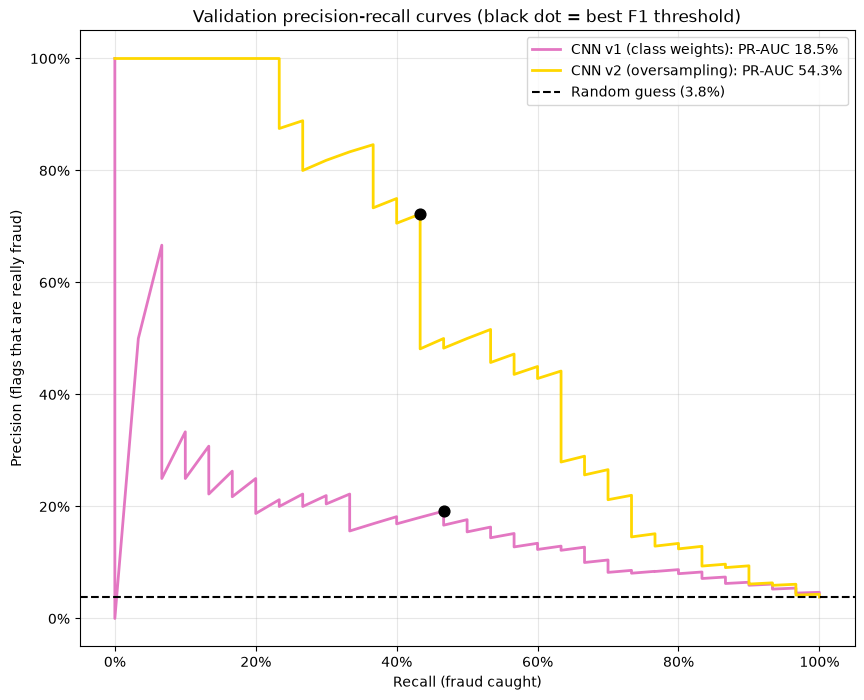

In [12]:
# Compares CNN v1 and CNN v2 on the validation set using precision-recall curves.
# Each model predicts a fraud probability for every validation image.
# The black dot marks the threshold with the best F1 for each model.
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculates the precision-recall curve and PR-AUC for each model on the validation set.
y_val = np.array(val_labels)
val_probs = {
    "CNN v1 (class weights)": model.predict(val_ds, verbose=0).ravel(),
    "CNN v2 (oversampling)": model_v2.predict(val_ds, verbose=0).ravel(),
}

# Plots the precision-recall curves for both models on the validation set and saves the figure.
plt.figure(figsize=(10, 8))
for (name, probs), colour in zip(val_probs.items(), ["tab:pink", "gold"]):
    precision, recall, thresholds = precision_recall_curve(y_val, probs)
    pr_auc = average_precision_score(y_val, probs)

    # Calculates F1 at every threshold and finds the best one.
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
    best = np.argmax(f1)

    plt.plot(recall, precision, label=f"{name}: PR-AUC {pr_auc * 100:.1f}%", color=colour, linewidth=2)
    plt.scatter(recall[best], precision[best], color="black", s=60, zorder=3)

    print(f"{name}: PR-AUC {pr_auc * 100:.1f}% | best F1 {f1[best] * 100:.1f}% "
          f"at threshold {thresholds[best]:.2f} (precision {precision[best] * 100:.1f}%, recall {recall[best] * 100:.1f}%)")

plt.axhline(y_val.mean(), color="black", linestyle="--", label=f"Random guess ({y_val.mean() * 100:.1f}%)")
plt.gca().xaxis.set_major_formatter(PercentFormatter(1.0))
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Recall (fraud caught)")
plt.ylabel("Precision (flags that are really fraud)")
plt.title("Validation precision-recall curves (black dot = best F1 threshold)")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig(RESULTS / "cnn_validation_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Threshold chosen on validation: 0.98

Always non-fraud (baseline)
  Accuracy:  93.4%
  Precision: 0.0%
  Recall:    0.0%
  F1:        0.0%

CNN v2, threshold 0.98
  Accuracy:  94.7%
  Precision: 73.7%
  Recall:    30.1%
  F1:        42.7%

CNN v2 test PR-AUC: 55.3% (random guess 6.6%)


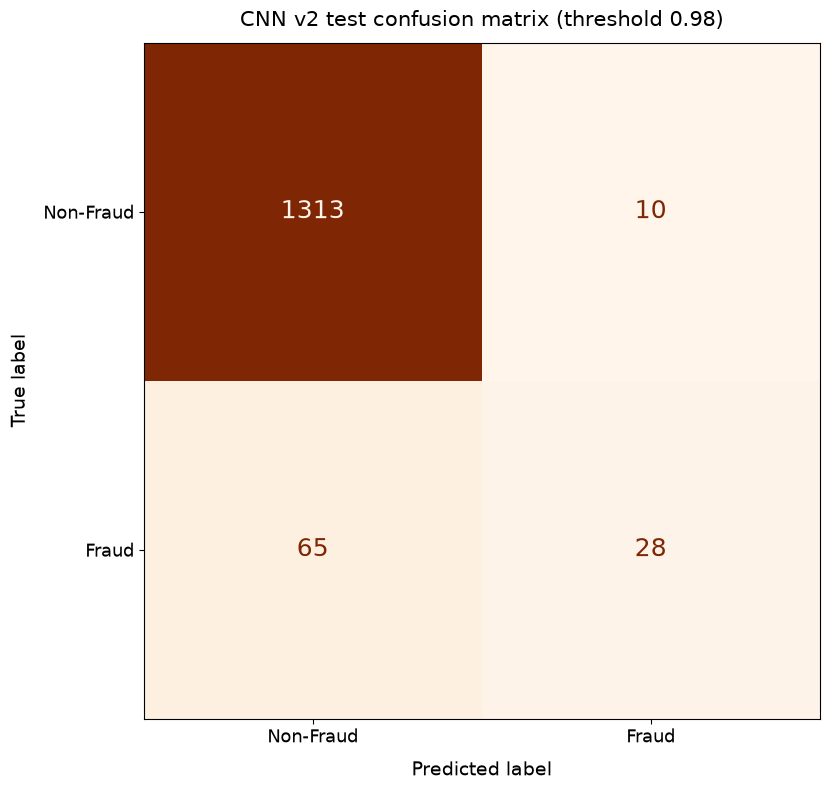

In [16]:
# Final evaluation of the chosen model (CNN v2) on the untouched test set.
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
confusion_matrix, ConfusionMatrixDisplay)

# Best-F1 threshold for v2 from the validation set
precision_v, recall_v, thresholds_v = precision_recall_curve(y_val, val_probs["CNN v2 (oversampling)"])
f1_v = 2 * precision_v[:-1] * recall_v[:-1] / (precision_v[:-1] + recall_v[:-1] + 1e-9)
threshold = thresholds_v[np.argmax(f1_v)]
print(f"Threshold chosen on validation: {threshold:.2f}")

# Prediction on the test set
y_test = np.array(test_labels)
test_probs = model_v2.predict(test_ds, verbose=0).ravel()
test_preds = (test_probs >= threshold).astype(int)

# Baseline: always predict non-fraud
baseline_preds = np.zeros_like(y_test)

results = {
    "Always non-fraud (baseline)": baseline_preds,
    f"CNN v2, threshold {threshold:.2f}": test_preds,
}
# Prints the accuracy, precision, recall and F1 for each model on the test set.
for name, preds in results.items():
    print(f"\n{name}")
    print(f"  Accuracy:  {accuracy_score(y_test, preds) * 100:.1f}%")
    print(f"  Precision: {precision_score(y_test, preds, zero_division=0) * 100:.1f}%")
    print(f"  Recall:    {recall_score(y_test, preds) * 100:.1f}%")
    print(f"  F1:        {f1_score(y_test, preds, zero_division=0) * 100:.1f}%")
print(f"\nCNN v2 test PR-AUC: {average_precision_score(y_test, test_probs) * 100:.1f}% (random guess {y_test.mean() * 100:.1f}%)")

# Confusion matrix
cm = confusion_matrix(y_test, test_preds)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=["Non-Fraud", "Fraud"]).plot(
    ax=ax, cmap="Oranges", colorbar=False, values_format="d", text_kw={"fontsize": 18}
)
ax.set_xlabel("Predicted label", fontsize=14, labelpad=10)
ax.set_ylabel("True label", fontsize=14, labelpad=10)
ax.tick_params(axis="both", labelsize=13)
ax.set_title(f"CNN v2 test confusion matrix (threshold {threshold:.2f})", fontsize=15, pad=12)
plt.tight_layout()
plt.savefig(RESULTS / "cnn_v2_test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Compares CNN v1 and CNN v2 with classical models (Logistic Regression, Random Forest, Decision Tree, Naive Bayes) on the same task.
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_recall_curve, average_precision_score, precision_score,
recall_score, f1_score, accuracy_score)

# Turns every image in dataset into 54 colour features
def colour_features(ds):
    X, y = [], []
    # Loops over the dataset to extract features from each image
    for images, labels in ds: 
        for img in images.numpy():
            feats = []
            for ch in range(3):
                channel = img[:, :, ch] # Extract the channel
                hist, _ = np.histogram(channel, bins=16, range=(0, 1)) # Compute histogram
                feats.extend(hist / hist.sum())
                feats.append(channel.mean())
                feats.append(channel.std())
            X.append(feats)
        y.extend(labels.numpy())
    return np.array(X), np.array(y)

# Extracts colour features from the training, validation and test datasets
X_train, y_train = colour_features(make_dataset(train_paths, train_labels))  # not shuffled, so results repeat
X_val, y_val = colour_features(val_ds)
X_test, y_test = colour_features(test_ds)
print("Feature shapes:", X_train.shape, X_val.shape, X_test.shape)

# Finds the threshold with the best F1 on the validation set
def best_threshold(y_true, probs):
    precision, recall, thresholds = precision_recall_curve(y_true, probs)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
    return thresholds[np.argmax(f1)]

# Scores a model on the test set using a given threshold
def test_scores(name, y_true, probs, threshold):
    preds = (probs >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_true, preds) * 100,
        "Precision": precision_score(y_true, preds, zero_division=0) * 100,
        "Recall": recall_score(y_true, preds) * 100,
        "F1": f1_score(y_true, preds, zero_division=0) * 100,
        "PR-AUC": average_precision_score(y_true, probs) * 100,
    }

# Compares classical models with CNN v2 on the test set using the same evaluation functions.
classical_models = {
    "Logistic Regression (colour features)": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)
    ),
    "Random Forest (colour features)": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
    "Decision Tree (colour features)": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=SEED
    ),
    "Naive Bayes (colour features)": GaussianNB(), 
}

# Scores each classical model on the test set and appends the results to a list of rows.
rows = []
for name, clf in classical_models.items():
    clf.fit(X_train, y_train)
    threshold = best_threshold(y_val, clf.predict_proba(X_val)[:, 1])
    rows.append(test_scores(name, y_test, clf.predict_proba(X_test)[:, 1], threshold))

# CNN v2, using the same functions so the comparison is fair
cnn_val_probs = model_v2.predict(val_ds, verbose=0).ravel()
cnn_test_probs = model_v2.predict(test_ds, verbose=0).ravel()
rows.append(test_scores("CNN v2 (oversampling)", y_test, cnn_test_probs, best_threshold(y_val, cnn_val_probs)))

cnn_v1_val_probs = model.predict(val_ds, verbose=0).ravel() # Predicts probabilities for validation set
cnn_v1_test_probs = model.predict(test_ds, verbose=0).ravel() # Predicts probabilities for test set
rows.append(test_scores("CNN v1 (class weights)", y_test, cnn_v1_test_probs, best_threshold(y_val, cnn_v1_val_probs))) 

# Baseline: always predict non-fraud
rows.append(test_scores("Always non-fraud (baseline)", y_test, np.zeros(len(y_test)), 0.5))

# Creates a DataFrame from the results and saves it to a CSV file.
results_table = pd.DataFrame(rows).round(1)
results_table["Threshold"] = [r["Threshold"] for r in rows]
results_table.to_csv(RESULTS / "image_model_comparison.csv", index=False)
results_table

Feature shapes: (4420, 54) (780, 54) (1416, 54)


,Model,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
0,Logistic Regression (colour features),0.61,78.3,8.8,24.7,13.0,8.6
1,Random Forest (colour features),0.23,90.8,28.2,25.8,27.0,25.5
2,Decision Tree (colour features),0.82,84.8,9.3,15.1,11.5,8.9
3,Naive Bayes (colour features),0.94,89.2,10.5,8.6,9.5,10.1
4,CNN v2 (oversampling),0.98,94.7,73.7,30.1,42.7,55.3
5,CNN v1 (class weights),0.86,87.1,23.2,41.9,29.9,25.2
6,Always non-fraud (baseline),0.50,93.4,0.0,0.0,0.0,6.6


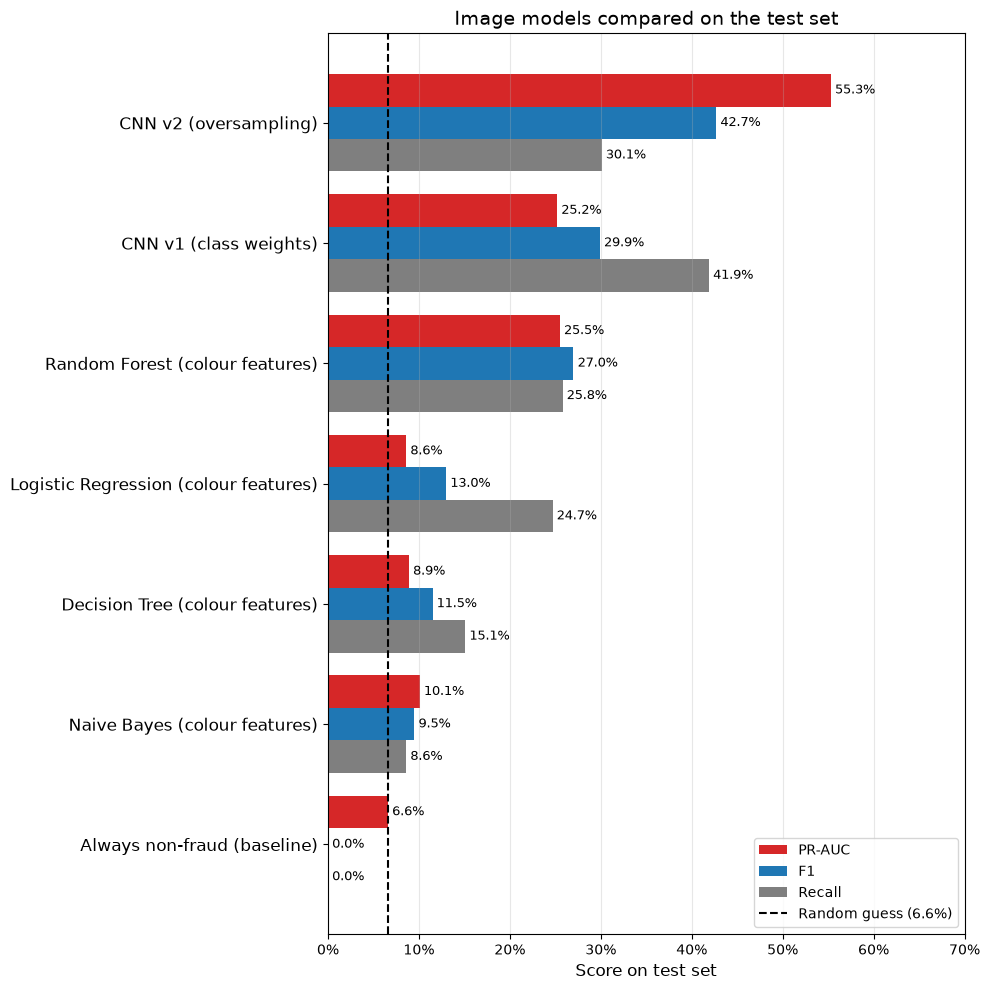

In [27]:
# Compares all image models on the test set using PR-AUC, F1 and recall.
# Recall is shown for completeness and dashed line is a random guess (PR-AUC = fraud rate in the test set).
from matplotlib.ticker import PercentFormatter

chart = results_table.sort_values("F1")

fig, ax = plt.subplots(figsize=(10, 10))
y_pos = np.arange(len(chart))
bar_height = 0.27

bars_recall = ax.barh(y_pos - bar_height, chart["Recall"], height=bar_height, label="Recall", color="tab:gray")
bars_f1 = ax.barh(y_pos, chart["F1"], height=bar_height, label="F1", color="tab:blue")
bars_auc = ax.barh(y_pos + bar_height, chart["PR-AUC"], height=bar_height, label="PR-AUC", color="tab:red")
for bars in [bars_recall, bars_f1, bars_auc]:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.axvline(y_test.mean() * 100, color="black", linestyle="--", label=f"Random guess ({y_test.mean() * 100:.1f}%)")
ax.set_yticks(y_pos)
ax.set_yticklabels(chart["Model"], fontsize=12)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlim(0, 70)
ax.set_xlabel("Score on test set", fontsize=12)
ax.set_title("Image models compared on the test set", fontsize=14)
ax.grid(axis="x", alpha=0.3)

# Legend in the same order as the bars (PR-AUC on top, then F1, then recall)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS / "image_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()